# Projeto 1

Charlie Alvez Cruz Brambilha- RA 198174 <br>
Letícia Palomero Rodrigues - RA 239038 <br>
Pedro Teruo Hidaka Luiz -RA 239643

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

##Parte 1


1.1

In [ ]:
# Amostras
X = pd.read_csv('sample_data/imageMNIST.csv', decimal=',').to_numpy() # (4999, 400)
y = pd.read_csv('sample_data/labelMNIST.csv').to_numpy()              # (4999, 1)

# X é a matriz onde cada linha representa um exemplo e cada coluna um pixel da imagem
# y é o vetor com o resultado esperado para cada linha de X

In [ ]:
# Sigmoide g(z) = 1 / (1 + e^(-z))
def sigmoide(z):
    return 1 / (1 + np.exp(-z))

In [ ]:
# Derivada da Sigmoide g'(z) = g(z) * (1 - g(z))
def derivadaSigmoide(z):
    return sigmoide(z) * (1 - sigmoide(z))

In [ ]:
# Função de Custo
# J(theta) = -1 / m [sum(y * log(h_theta) + (1 - y)log(1 - h_theta))]
def computarCusto(X, y, theta, tamanho_camada_entrada, tamanho_camada_escondida, numero_saidas, Lambda):
    # dividindo o vetor theta em theta1 e theta2
    theta1 = theta[:((tamanho_camada_entrada+1) * tamanho_camada_escondida)].reshape(tamanho_camada_escondida, tamanho_camada_entrada + 1)
    theta2 = theta[((tamanho_camada_entrada+1) * tamanho_camada_escondida):].reshape(numero_saidas, tamanho_camada_escondida +  1)

    m = X.shape[0]
    J = 0                                # Parte do somatório da função de custo
    X = np.hstack((np.ones((m, 1)), X))  # Adicionando o bias (x0 = 1) na 1° coluna do X
    y10 = np.zeros((m, numero_saidas))   # Matriz com os vetores y das predições

    # Forward Propagation
    a2 = sigmoide(X @ theta1.T)           # a2 = g(z2) = g(theta1 x X)
    a2 = np.hstack((np.ones((m, 1)), a2)) # Adicionando o bias (x0 = 1) na 1° coluna do a1
    a3 = sigmoide(a2 @ theta2.T)          # a3 = g(z3) = g(theta2 x a2)
    a3 = np.clip(a3, 1e-12, 1 - 1e-12)    #

    for i in range(1, numero_saidas+1):
        y10[:,i-1][:,np.newaxis] = np.where(y == i, 1, 0) # Transforma o vetor y numa matriz de vetores onde índice do resultado esperado é 1 e, caso contrário, 0
    for j in range(numero_saidas):
        J = J + sum(-y10[:,j] * np.log(a3[:,j]) - (1-y10[:,j]) * np.log(1 - a3[:,j]))

    J = 1 / m * J # Função de custo
    J_regularizada = J + Lambda / (2 * m) * (np.sum(theta1[:,1:]**2) + np.sum(theta2[:,1:]**2)) # Função de custo regularizada

    D1 = np.zeros((theta1.shape)) # dJ(theta1) / dtheta
    D2 = np.zeros((theta2.shape)) # dJ(theta1) / dtheta
    Delta1 = np.zeros((theta1.shape)) # dJ(theta1) / dtheta
    Delta2 = np.zeros((theta2.shape)) # dJ(theta1) / dtheta

    # Backpropagation
    for i in range(m):
        xi = X[i,:]
        a2i = a2[i,:]
        a3i = a3[i,:]
        delta3 = a3i - y10[i,:]                                                       # delta3 = a3 - y
        delta2 = theta2.T @ delta3.T * derivadaSigmoide(np.hstack((1,xi @ theta1.T))) # delta2 = (theta2.T x delta3) * (X * theta1)
        Delta1 = Delta1 + delta2[1:][:,np.newaxis] @ xi[:,np.newaxis].T               # Delta1 = Delta1 + delta2 x X.T
        Delta2 = Delta2 + delta3.T[:,np.newaxis] @ a2i[:,np.newaxis].T                # Delta2 = Delta2 + delta3 x a2.T

    # D = 1 / m Delta
    D1 = 1 / m * Delta1
    D2 = 1 / m * Delta2

    gradiente1_regularizado = D1 + (Lambda / m) * np.hstack((np.zeros((theta1.shape[0], 1)), theta1[:,1:])) # Regularizando o gradiente1
    gradiente2_regularizado = D2 + (Lambda / m) * np.hstack((np.zeros((theta2.shape[0], 1)), theta2[:,1:])) # Regularizando o gradiente2

    return J, D1, D2, J_regularizada, gradiente1_regularizado, gradiente2_regularizado

In [ ]:
# Função para inicializar os thetas com pesos aleatórios (Inicialização de Glorot/Xavier)
def inicializarPesosAleatorios(tamanho_camada_entrando, tamanho_camada_saindo):
    epi = (6**(1 / 2)) / (tamanho_camada_entrando + tamanho_camada_saindo)**(1 / 2)
    W = np.random.rand(tamanho_camada_saindo, tamanho_camada_entrando+1) * (2 * epi) - epi
    return W

In [ ]:
def gradienteDescendente(X, y, theta, alpha, numero_iteracoes, Lambda, tamanho_camada_entrada, tamanho_camada_escondida, numero_saidas):
    # dividindo o vetor theta em theta1 e theta2
    theta1 = theta[:((tamanho_camada_entrada+1) * tamanho_camada_escondida)].reshape(tamanho_camada_escondida, tamanho_camada_entrada + 1)
    theta2 = theta[((tamanho_camada_entrada+1) * tamanho_camada_escondida):].reshape(numero_saidas, tamanho_camada_escondida + 1)

    m = len(y)
    J_historico = [] # Vetor com o histórico dos custos J(theta)

    # theta = theta - alpha * dJ(theta) / dtheta
    for i in range(numero_iteracoes):
        theta = np.append(theta1.flatten(), theta2.flatten())
        custo, gradiente1, gradiente2 = computarCusto(X, y, theta, tamanho_camada_entrada, tamanho_camada_escondida, numero_saidas, Lambda)[3:] # Obtendo dJ(theta) / dtheta
        # Batch Gradient Descent
        theta1 = theta1 - (alpha * gradiente1) # Ajustando os valores de theta1 com o gradiente1
        theta2 = theta2 - (alpha * gradiente2) # Ajustando os valores de theta2 com o gradiente2
        J_historico.append(custo)

    theta_final = np.append(theta1.flatten(), theta2.flatten())
    return theta_final, J_historico

In [ ]:
# Faz a predição dos y a partir de uma matriz X e dos thetas obtidos no gradiente descendente
def adivinhar(X, theta1, theta2):
    m = X.shape[0]
    X = np.hstack((np.ones((m, 1)), X))   # Adicionando o bias (x0 = 1) na 1° coluna do X

    a1 = sigmoide(X @ theta1.T)           # Calculando a1 = g(z1) com z1 = theta1.T x X
    a1 = np.hstack((np.ones((m, 1)), a1)) # Adicionando o bias (x0 = 1) na 1° coluna do a1
    a2 = sigmoide(a1 @ theta2.T)          # Calculando a2 = g(z2) com z2 = theta2.T x a1

    return np.argmax(a2, axis=1) + 1      # Retorna um vetor com o maior valor de cada coluna de a2 (h_theta)

In [ ]:
# Definindo a arquitetura da rede:
arquitetura = [400, 25, 10] # [tamanho_camada_entrada, tamanho_camada_escondida, numero_saidas]
# Total de 3 camadas: entrada, 1 escondida, saída

In [ ]:
# Inicializando theta com valores aleatórios próximos de 0
theta1_inicial = inicializarPesosAleatorios(arquitetura[0], arquitetura[1])
theta2_inicial = inicializarPesosAleatorios(arquitetura[1], arquitetura[2])
theta = np.append(theta1_inicial.flatten(), theta2_inicial.flatten())

hiperparametros = [0.8, 800, 1] # [alpha, numero_iteracoes,Lambda]

# Usando gradiente descendente para obter os thetas
theta,J_historico = gradienteDescendente(X, y, theta, hiperparametros[0], hiperparametros[1], hiperparametros[2], arquitetura[0], arquitetura[1], arquitetura[2])
theta1 = theta[:((arquitetura[0]+1) * arquitetura[1])].reshape(arquitetura[1], arquitetura[0] + 1) # theta obtido na camada 1 (entrada)
theta2 = theta[((arquitetura[0]+1) * arquitetura[1]):].reshape(arquitetura[2], arquitetura[1] + 1) # theta obtido na camada 2 (escondida)

# J_historico                     # (800, )
# theta                           # (10285, 1) = 25 * 401 + 10 * 26
# theta1                          # (25, 401)
# theta2                          # (10, 26)
# np.hstack((np.ones((m, 1)), X)) # (4999, 401): X com o enviezamento

In [ ]:
resultado = adivinhar(X, theta1, theta2)[:, np.newaxis]                        # Obtendo as previsões para X a partir dos thetas calculados anteriormente
print("Precisão:", sum(resultado == y)[0] / np.shape(resultado)[0] * 100, "%") # Precisão das previsões

Precisão: 94.89897979595919 %


255 classificados incorretamente (5.10%)


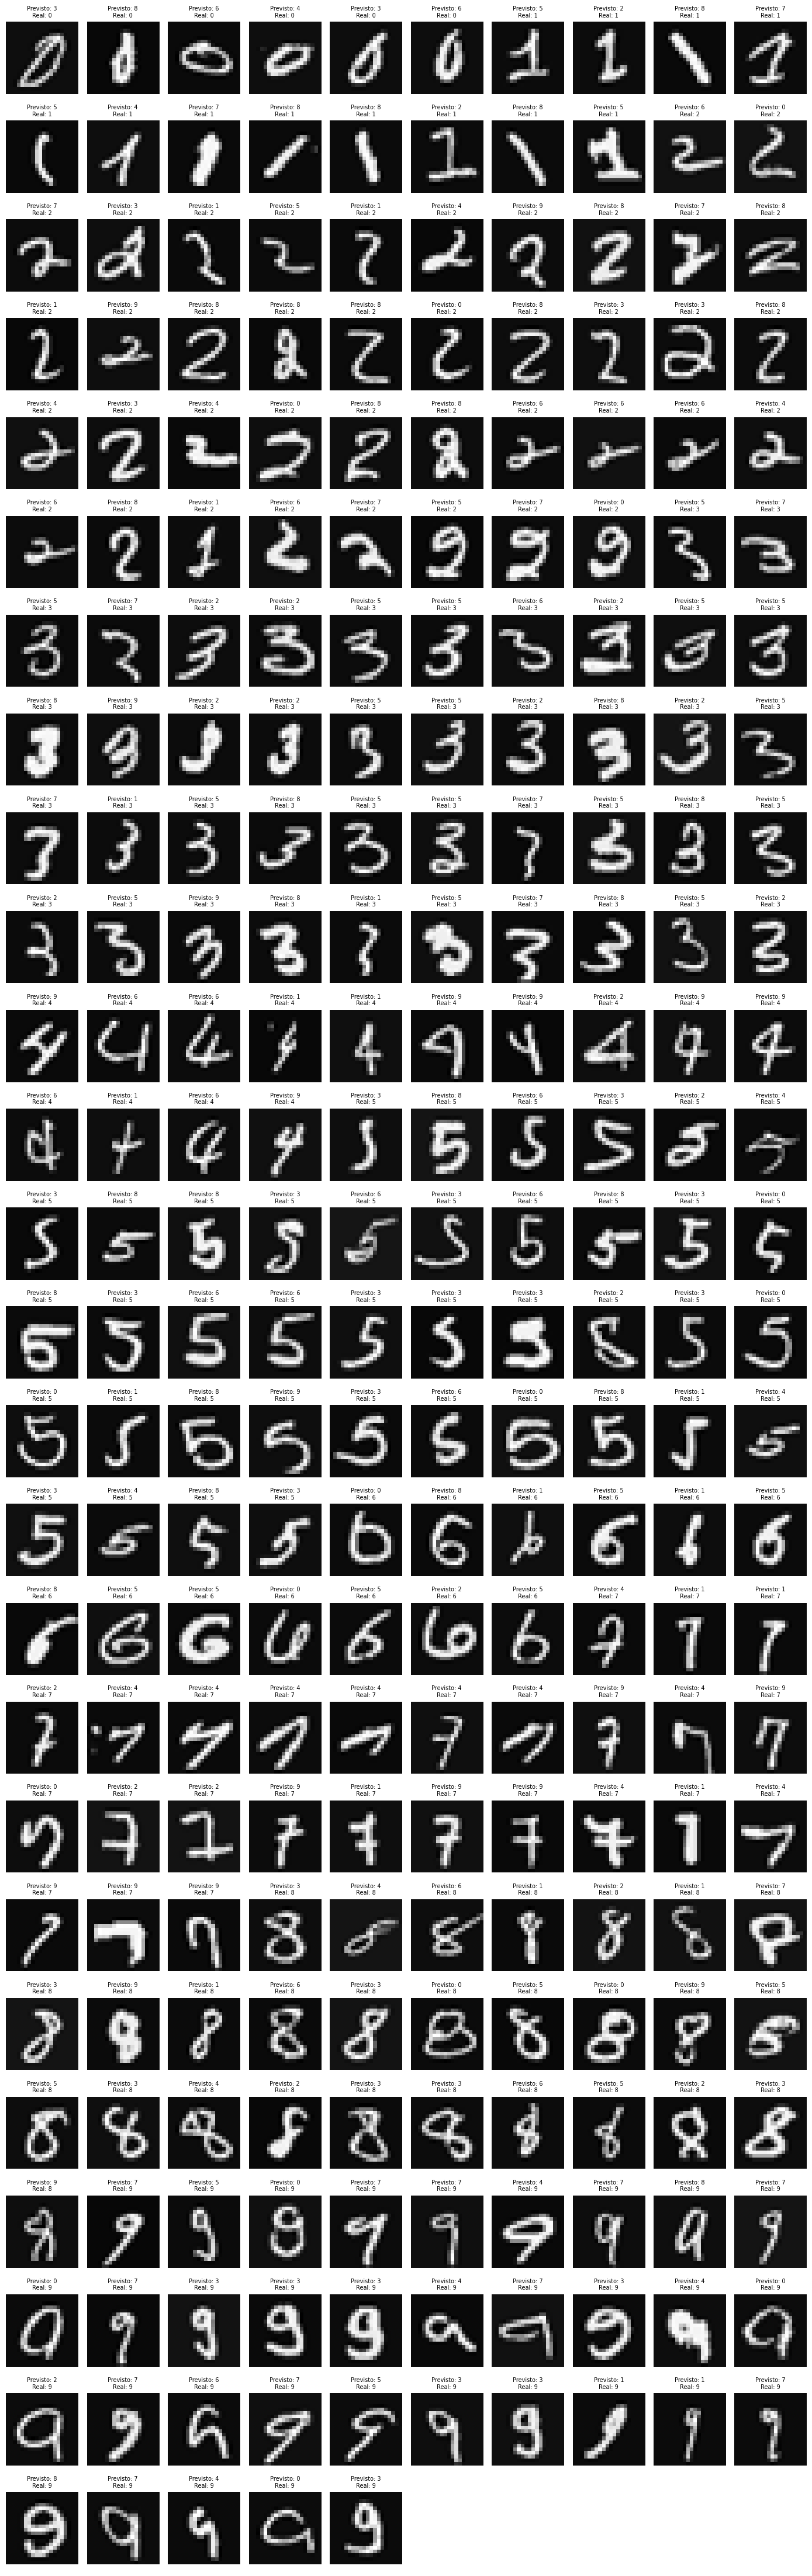

In [ ]:
erros = np.where(resultado.ravel() != y.ravel())[0] # Cria um vetor com as predições erradas (!= y)
quantidade_erros = len(erros)
porcentagem_erros = quantidade_erros / len(y) * 100

print(f"{quantidade_erros} classificados incorretamente ({porcentagem_erros:.2f}%)")

# Define as dimensões da figura com as predições erradas
colunas = 10
linhas = int(np.ceil(quantidade_erros / colunas))

# Criando a figura
fig, eixos = plt.subplots(linhas, colunas, figsize=(14, linhas * 1.7))
eixos = eixos.ravel()

# Exibindo cada imagem classificada errada como uma subfigura
for k in range(quantidade_erros):
    indice = erros[k]

    imagem = X[indice].reshape(20, 20, order="F")
    previsto = resultado[indice][0] % 10
    real = y[indice][0] % 10

    eixos[k].imshow(imagem, cmap="gray")
    eixos[k].set_title(f"Previsto: {previsto}\nReal: {real}", fontsize=7)
    eixos[k].axis("off")

for k in range(quantidade_erros, len(eixos)):
    eixos[k].axis("off")

# Mostrando a figura
plt.tight_layout()
plt.show()

1.2


In [ ]:
# Função que calcula o gradiente pelo método numérico e a diferença entre ele o gradiente obtido pelo backpropagation
def checagemGradiente(X, y, theta, tamanho_camada_entrada, tamanho_camada_escondida, numero_saidas, Lambda, epsilon):
    n = len(theta)
    gradiente_numericamente = np.zeros(n)

    # Calculando o gradiente numéricamente
    for i in range(n):
        theta_mais = theta.copy()
        theta_menos = theta.copy()

        theta_mais[i] += epsilon  # theta com uma variação + epsilon
        theta_menos[i] -= epsilon # theta com uma variação - epsilon

        J_mais = computarCusto(X, y, theta_mais, tamanho_camada_entrada, tamanho_camada_escondida, numero_saidas, Lambda)[3]   # J / custo do theta com uma variação + epsilon
        J_menos = computarCusto(X, y, theta_menos, tamanho_camada_entrada, tamanho_camada_escondida, numero_saidas, Lambda)[3] # J / custo do theta com uma variação - epsilon

        gradiente_numericamente[i] = (J_mais - J_menos) / (2 * epsilon)

    # Gradiente pelo backpropagation
    _, _, _, _, gradiente1_regularizado, gradiente2_regularizado = computarCusto(X, y, theta, tamanho_camada_entrada, tamanho_camada_escondida, numero_saidas, Lambda)
    gradiente_backpropagation = np.append(gradiente1_regularizado.flatten(), gradiente2_regularizado.flatten())

    # Cálculo do erro entre o numérico e o backpropagation
    # erro = |numericamente - backpropagation| / |numericamente| + |backpropagation|
    erro = (np.linalg.norm(gradiente_numericamente - gradiente_backpropagation) / (np.linalg.norm(gradiente_numericamente) + np.linalg.norm(gradiente_backpropagation)))

    return gradiente_numericamente, gradiente_backpropagation, erro

In [ ]:
# AVISO: essa parte demoraria para rodar (ela roda a computarCusto 2*n +1 vezes, para a rede completa, n = 10285) então estamos usando uma "versão reduzida"
epsilon = 10**(-4)

# Pegando os 3 primeiros x com apenas 3 atributos e os 3 primeiros y
X_checagem = X[:3, :3] # (3, 3)
y_checagem = y[:3]     # (3, 1)

# arquitetura com o tamanho reduzido para a checagem
tamanho_camada_entrada_checagem = 3
tamanho_camada_escondida_checagem = 5
numero_saidas_checagem = 3

theta1_checagem = inicializarPesosAleatorios(3, 5)   # (5, 4)
theta2_checagem = inicializarPesosAleatorios(5, 3)   # (3, 6)
theta_checagem  = np.append(theta1_checagem.flatten(), theta2_checagem.flatten())  # (38, )

gradiente_aproximado, gradiente_backpropagation, erro = checagemGradiente(X_checagem, y_checagem, theta_checagem, tamanho_camada_entrada_checagem, tamanho_camada_escondida_checagem, numero_saidas_checagem, hiperparametros[2], epsilon)

#print(gradiente_aproximado)
#print(gradiente_backpropagation)
print("O erro obtido comparando o gradiente obtido pelo método numérico e o backpropagation é de:", erro)

O erro obtido comparando o gradiente obtido pelo método numérico e o backpropagation é de: 9.08397873921808e-11


1.3


In [ ]:
from scipy.optimize import minimize

In [ ]:
# Função objetivo a ser minimizada (usada como parâmetro no minimize)
def fun(theta_flat, X, y, tamanho_camada_entrada, tamanho_camada_escondida, numero_saidas, Lambda):
    return computarCusto(X, y, theta_flat, tamanho_camada_entrada, tamanho_camada_escondida, numero_saidas,Lambda)[3]

In [ ]:
# Método para calcuar o gradiente do vetor (usada como parâmetro no minimize)
def jac(theta_flat, X, y, tamanho_camada_entrada, tamanho_camada_escondida, numero_saidas, Lambda):
    _, _, _, _, gradiente1_regularizado, gradiente2_regularizado = computarCusto(X, y, theta_flat, tamanho_camada_entrada, tamanho_camada_escondida, numero_saidas, Lambda)
    return np.append(gradiente1_regularizado.flatten(), gradiente2_regularizado.flatten())

In [ ]:
# Essa célula demora bastante para executar (geralmente + 30 min)

# Cuidado ao alterar a quantidade de lambdas e de iterações, dependendo, pode levar MÚLTIPLAS HORAS
lambdas = [0, 0.1, 1, 10]
iteracoes = [50, 100, 200]

resultados = []

# Variando os Lambdas e as iterações
for l in lambdas:
    for i in iteracoes:
        # Inicialização aleatória
        theta1 = inicializarPesosAleatorios(arquitetura[0], arquitetura[1])
        theta2 = inicializarPesosAleatorios(arquitetura[1], arquitetura[2])
        theta = np.append(theta1.flatten(), theta2.flatten())

        # Usando o scipy.optimize.minimize
        resultado_minimize = minimize(fun=fun, x0=theta, args=(X, y, arquitetura[0], arquitetura[1], arquitetura[2], l), jac=jac, method='CG', options={'maxiter': i, 'disp': True})

        # Pegando os thetas obtidos pelo minimize
        theta1 = resultado_minimize.x[:((arquitetura[0] + 1) * arquitetura[1])].reshape(arquitetura[1], arquitetura[0] + 1)
        theta2 = resultado_minimize.x[((arquitetura[0] + 1) * arquitetura[1]):].reshape(arquitetura[2], arquitetura[1] + 1)

        #  # Obtendo as previsões para X a partir dos thetas calculados com minimize e calculando sua precisão
        resultado = adivinhar(X, theta1, theta2)[:, np.newaxis]
        precisao  = np.mean(resultado == y) * 100

        resultados.append({'lambda': l, 'maxiter': i, 'Iterações': resultado_minimize.nit, 'Custo': resultado_minimize.fun, 'Precisão': precisao})
        print(f"λ={l:<4} maxiter={i:<4} "
              f"| nit={resultado_minimize.nit:<4} | J={resultado_minimize.fun:.4f} "
              f"| Precisão={precisao:.2f}%")
        print("Convergiu:", resultado_minimize.success)
        print("Mensagem:", resultado_minimize.message)
        print()

# Tabela final
df = pd.DataFrame(resultados)
print(df.pivot_table(index='lambda', columns='maxiter', values='Precisão', aggfunc='mean').round(2))

/usr/local/lib/python3.13/dist-packages/scipy/optimize/_minimize.py:777: OptimizeWarning: Maximum number of iterations has been exceeded.
  res = _minimize_cg(fun, x0, args, jac, callback, **options)


         Current function value: 0.211677
         Iterations: 50
         Function evaluations: 115
         Gradient evaluations: 115
λ = 0, maxiter = 50
Convergiu: False
Mensagem: Maximum number of iterations has been exceeded.
λ=0    maxiter=50   | nit=50   | J=0.2117 | Precisão=97.60%
         Current function value: 0.023132
         Iterations: 100
         Function evaluations: 279
         Gradient evaluations: 279
λ = 0, maxiter = 100
Convergiu: False
Mensagem: Maximum number of iterations has been exceeded.
λ=0    maxiter=100  | nit=100  | J=0.0231 | Precisão=99.92%
         Current function value: 0.001100
         Iterations: 200
         Function evaluations: 616
         Gradient evaluations: 616
λ = 0, maxiter = 200
Convergiu: False
Mensagem: Maximum number of iterations has been exceeded.
λ=0    maxiter=200  | nit=200  | J=0.0011 | Precisão=100.00%
         Current function value: 0.298872
         Iterations: 50
         Function evaluations: 126
         Gradient eva

1.4


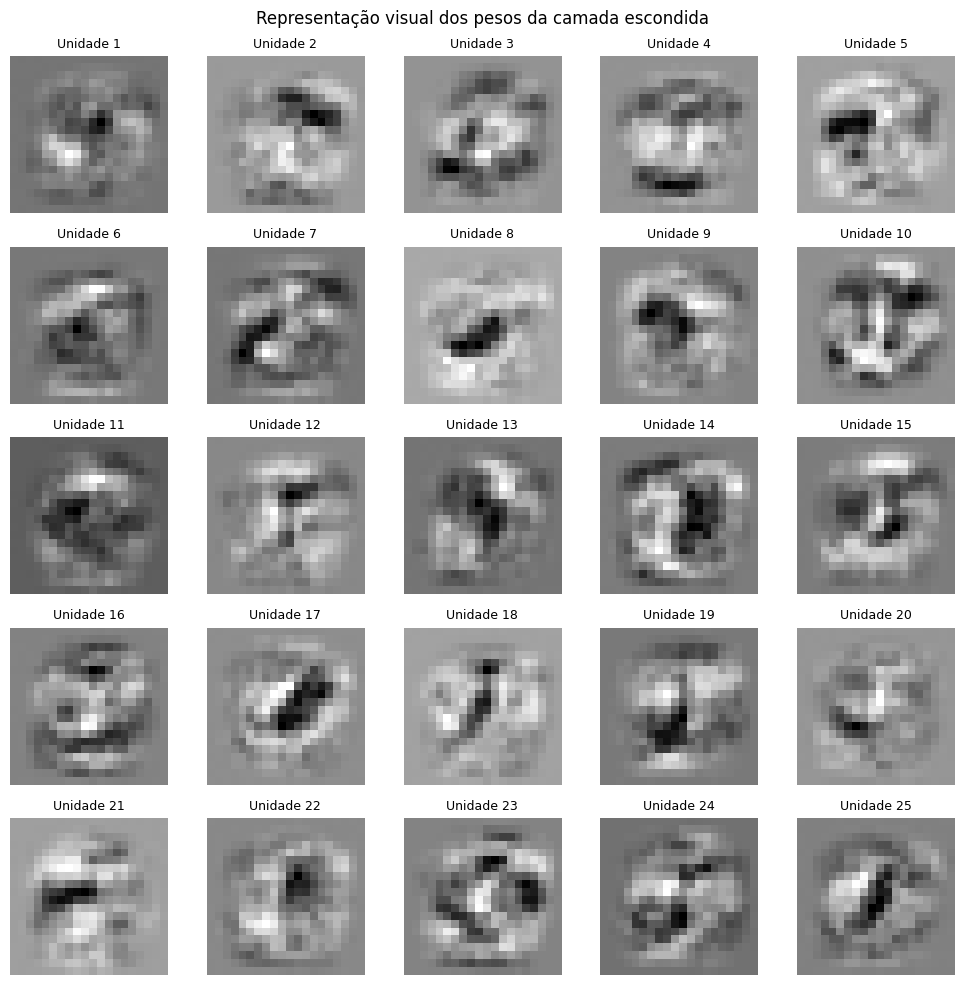

In [ ]:
# Mostrando as imagens obtidas em cada uma das camadas escondidas
# Removendo a coluna do bias para recuperar os 400 atributos da imagem 20 x 20
pesos_sem_bias = theta1[:, 1:]
imagens = pesos_sem_bias.reshape(arquitetura[1], 20, 20, order="F")

imagens_normalizadas = np.zeros_like(imagens)

# Normalizando as imagens
for i in range(arquitetura[1]):
    imagem = imagens[i]
    minimo, maximo = imagem.min(), imagem.max()

    if(maximo - minimo > 0):
        imagens_normalizadas[i] = (imagem - minimo) / (maximo - minimo)
    else:
        imagens_normalizadas[i] = imagem

# Definindo o posicionamento das imagens
colunas = 5
linhas = int(np.ceil(arquitetura[1] / colunas)) # 25/5 = 5 linhas

# Criando a figura
fig, eixos = plt.subplots(linhas, colunas, figsize=(10, 10))
eixos = eixos.ravel()

for i in range(arquitetura[1]):
    eixos[i].imshow(imagens_normalizadas[i], cmap='gray', interpolation='nearest')
    eixos[i].set_title(f"Unidade {i+1}", fontsize=9)
    eixos[i].axis('off')

plt.suptitle("Representação visual dos pesos da camada escondida", fontsize=12)
plt.tight_layout()
plt.show()

# Parte 2

## 2.1

In [ ]:
m = X.shape[0] # 4999
indices = np.random.permutation(m) # embaralha os Xi para não pegar eles em ordem

# Divisão dos cojuntos
proporcao = [0.6, 0.2, 0.2] # [treino, valildacao, teste]

# Separa os ids da lista para pegar os dados de X e y
ids_treino = indices[:int(proporcao[0] * m)]                                             # pega os ids até 0.6 * total
ids_validacao    = indices[int(proporcao[0] * m):int((proporcao[0] + proporcao[1]) * m)] # pega os ids entre 0.6 * total e (0.6 + 0.2) * total
ids_teste  = indices[int((proporcao[0] + proporcao[1]) * m):]                            # pega os ids a partir de (0.6 + 0.2) * total

# Separando X e y de treino, validação e teste
X_treino, y_treino = X[ids_treino], y[ids_treino]
X_validacao, y_validacao = X[ids_validacao], y[ids_validacao]
X_teste,  y_teste  = X[ids_teste],  y[ids_teste]

# print(X_treino.shape, y_treino.shape)          # (2999, 400) (2999, 1)
# print(X_validacao.shape,    y_validacao.shape) # (1000, 400) (1000, 1)
# print(X_teste.shape,  y_teste.shape)           # (1000, 400) (1000, 1)

In [ ]:
# Calcula a porcetagem de acertos
def precisao(X, y, theta1, theta2):
    resultado = adivinhar(X, theta1, theta2)[:, np.newaxis]
    return np.mean(resultado == y) * 100

In [ ]:
# Usando apenas o conjunto de treino
# Inicializando theta com valores aleatórios próximos de 0
theta1_inicial = inicializarPesosAleatorios(arquitetura[0], arquitetura[1])
theta2_inicial = inicializarPesosAleatorios(arquitetura[1], arquitetura[2])
theta = np.append(theta1_inicial.flatten(), theta2_inicial.flatten())

# Usando gradiente descendente para obter os thetas
theta, J_historico = gradienteDescendente(X_treino, y_treino, theta, hiperparametros[0], hiperparametros[1], hiperparametros[2], arquitetura[0], arquitetura[1], arquitetura[2])
theta1 = theta[:((arquitetura[0]+1) * arquitetura[1])].reshape(arquitetura[1], arquitetura[0] + 1) # theta obtido na camada 1 (entrada)
theta2 = theta[((arquitetura[0]+1) * arquitetura[1]):].reshape(arquitetura[2], arquitetura[1] + 1) # theta obtido na camada 2 (escondida)

In [ ]:
# Custo (J_theta) regularizado
J_treino = computarCusto(X_treino, y_treino, theta, arquitetura[0], arquitetura[1], arquitetura[2], hiperparametros[2])[3]
J_validacao = computarCusto(X_validacao, y_validacao, theta, arquitetura[0], arquitetura[1], arquitetura[2], hiperparametros[2])[3]
J_teste  = computarCusto(X_teste,  y_teste,  theta, arquitetura[0], arquitetura[1], arquitetura[2], hiperparametros[2])[3]

# Precisão dos conjutos de teste / validação / treino
precisao_treino = precisao(X_treino, y_treino, theta1, theta2)
precisao_validacao = precisao(X_validacao, y_validacao, theta1, theta2)
precisao_teste  = precisao(X_teste,  y_teste,  theta1, theta2)

# Erro dos conjutos de teste / validação / treino
erro_treino = 100 - precisao_treino
erro_validacao    = 100 - precisao_validacao
erro_teste  = 100 - precisao_teste

# Resumo
print(f"{'Conjunto':<12} {'Custo J':>10} {'Acurácia':>10} {'Erro':>10}")
print("-" * 46)
print(f"{'Treino':<12} {J_treino:>10.4f} {precisao_treino:>9.2f}% {erro_treino:>9.2f}%")
print(f"{'Validação':<12} {J_validacao:>10.4f} {precisao_validacao:>9.2f}% {erro_validacao:>9.2f}%")
print(f"{'Teste':<12} {J_teste:>10.4f} {precisao_teste:>9.2f}% {erro_teste:>9.2f}%")

## 2.2

In [ ]:
# Calcula a porcentagem de erro
def erro_classificacao(X, y, theta1, theta2):
    resultado = adivinhar(X, theta1, theta2)[:, np.newaxis]
    return (1 - np.mean(resultado == y)) * 100

In [ ]:
# Um pouco demorado de executar
# Cálculo da curva de aprendizado
tamanhos = [50, 100, 200, 500, 1000, 1500, 2000, len(X_treino)] # tamnhos de conjuntos de dados
# Quanto mais tamanhos melhor para fazer o gráfico mas fica mais demorado de executar

erros_treino = []
erros_validacao = []

# Calcula os resultados para diferentes tamanhos de conjuntos
for n in tamanhos:
    # pegando os n primeiros x e y
    X_subconjunto = X_treino[:n]
    y_subconjunto = y_treino[:n]

    # Inicializando theta com valores aleatórios próximos de 0
    theta1_inicial = inicializarPesosAleatorios(arquitetura[0], arquitetura[1])
    theta2_inicial = inicializarPesosAleatorios(arquitetura[1], arquitetura[2])
    theta = np.append(theta1_inicial.flatten(), theta2_inicial.flatten())

    # Usando gradiente descendente para obter os thetas
    theta, _ = gradienteDescendente(X_subconjunto, y_subconjunto, theta, hiperparametros[0], hiperparametros[1], hiperparametros[2], arquitetura[0], arquitetura[1], arquitetura[2])
    theta1 = theta[:((arquitetura[0]+1) * arquitetura[1])].reshape(arquitetura[1], arquitetura[0] + 1) # theta obtido na camada 1 (entrada)
    theta2 = theta[((arquitetura[0]+1) * arquitetura[1]):].reshape(arquitetura[2], arquitetura[1] + 1) # theta obtido na camada 2 (escondida)

    # Calculando os erros de treino e validação
    erro_treino = erro_classificacao(X_subconjunto, y_subconjunto, theta1, theta2)
    erro_validacao = erro_classificacao(X_validacao, y_validacao, theta1, theta2)

    erros_treino.append(erro_treino)
    erros_validacao.append(erro_validacao)

    print(f"n = {n:>5}  |  Erro de Treino = {erro_treino:6.2f}%  |  Erro de Validação = {erro_validacao:6.2f}%")

# Criando a figura
plt.figure(figsize=(8, 5))
plt.plot(tamanhos, erros_treino, 'o-', label='Erro de treino',   color='steelblue')
plt.plot(tamanhos, erros_validacao,    's-', label='Erro de validação', color='firebrick')

plt.xlabel('Tamanho do conjunto de treino (n)')
plt.ylabel('Erro (%)')
plt.title('Curva de aprendizado')
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

## 2.3

In [ ]:
lambdas = [0, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]
numero_iteracoes = 400 # o número de iterações foi reduzido para demorar menos para rodar
erros_validacao = []

# Calcula os resultados para diferentes valores de lambda
for l in lambdas:
    # Inicializando theta com valores aleatórios próximos de 0
    theta1_inicial = inicializarPesosAleatorios(arquitetura[0], arquitetura[1])
    theta2_inicial = inicializarPesosAleatorios(arquitetura[1], arquitetura[2])
    theta = np.append(theta1_inicial.flatten(), theta2_inicial.flatten())

    # Usando gradiente descendente para obter os thetas
    theta, _ = gradienteDescendente(X_treino, y_treino, theta, hiperparametros[0], numero_iteracoes, l, arquitetura[0], arquitetura[1], arquitetura[2])
    theta1 = theta[:((arquitetura[0]+1) * arquitetura[1])].reshape(arquitetura[1], arquitetura[0] + 1) # theta obtido na camada 1 (entrada)
    theta2 = theta[((arquitetura[0]+1) * arquitetura[1]):].reshape(arquitetura[2], arquitetura[1] + 1) # theta obtido na camada 2 (escondida)

    # Erro de validação
    erro_validação = erro_classificacao(X_validacao, y_validacao, theta1, theta2)
    erros_validacao.append(erro_validação)

    print(f"λ = {l:<6} | Erro de Validação = {erro_validação:6.2f}%")

In [ ]:
id_otimo = int(np.argmin(erros_validacao)) # pega o id do lambda que teve o menor erro
lambda_otimo = lambdas[id_otimo]
erro_validacao_otimo = erros_validacao[id_otimo]

print(f"\nλ* = {lambda_otimo}  (Erro de Validação = {erro_validacao_otimo:.2f}%)")

# Criando a figura
plt.figure(figsize=(8, 5))
plt.semilogx(lambdas[1:], erros_validacao[1:], 'o-', color='firebrick', label='λ > 0')
plt.axhline(y=erros_validacao[0], color='steelblue', linestyle='--', label='λ = 0')
plt.plot([lambdas[1]], [erros_validacao[1]], 'o', color='firebrick')
plt.semilogx(lambda_otimo, erro_validacao_otimo, 'k*', markersize=16, label=f'λ* = {lambda_otimo}')

plt.xlabel('λ (log)')
plt.ylabel('Erro de validação (%)')
plt.title('Erro de validação em função de λ')
plt.grid(alpha=0.3, which='both')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Treinando usando o lambda ótimo
# Inicializando theta com valores aleatórios próximos de 0
theta1_inicial = inicializarPesosAleatorios(arquitetura[0], arquitetura[1])
theta2_inicial = inicializarPesosAleatorios(arquitetura[1], arquitetura[2])
theta = np.append(theta1_inicial.flatten(), theta2_inicial.flatten())

# Usando gradiente descendente para obter os thetas
theta, _ = gradienteDescendente(X_treino, y_treino, theta, hiperparametros[0], numero_iteracoes, lambda_otimo, arquitetura[0], arquitetura[1], arquitetura[2])
theta1 = theta[:((arquitetura[0] + 1) * arquitetura[1])].reshape(arquitetura[1], arquitetura[0] + 1)
theta2 = theta[((arquitetura[0] + 1) * arquitetura[1]):].reshape(arquitetura[2], arquitetura[1] + 1)

precisao_theta_otimo = precisao(X_teste, y_teste, theta1, theta2)
erro_theta_otimo = 100 - precisao_theta_otimo

print(f"Lambda ótimo: {lambda_otimo}")
print(f"Erro de validação: {erro_validacao_otimo:.2f}%")
print(f"Precisão no teste: {precisao_theta_otimo:.2f}%")
print(f"Erro no teste: {erro_theta_otimo:.2f}%")